# Information Theory: From Entropy to Data Compression

## Introduction

In the [previous article](https://blog.vikrampawar.com/how-do-we-quantify-information.html), we developed a measure of the information gained from an observation and introduced Shannon entropy, the average information we expect to gain before observing an outcome.

Consider a coin that lands on heads 80% of the time. Its entropy is approximately 0.722 bits per toss. If we toss it 10,000 times, the simplest way to store the results is to represent each head with a `1` and each tail with a `0`. That requires exactly 10,000 bits.

But the expected information content of those 10,000 tosses is only about 7,219 bits. Could we store the sequence using substantially fewer than 10,000 bits and still recover every toss exactly?

Before we investigate compression, we need to understand how much information a *sequence* of observations contains.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('../mplstyle/blog.mplstyle')
plt.rcParams.update({
    'figure.figsize': (8, 4),
    'axes.grid': True,
    'grid.alpha': 0.18,
    'font.size': 11,
})

random_generator = np.random.default_rng(2026)


def information_content(probabilities):
    return -np.log2(probabilities)


heads_probability = 0.8
coin_probabilities = np.array([1 - heads_probability, heads_probability])

## Information Content of a Sequence

Let's represent heads with `1` and tails with `0`. For our biased coin, the probabilities of heads and tails are 0.8 and 0.2, respectively.

Suppose we observe the sequence `110`: two heads followed by a tail. Since the tosses are independent, the probability of observing this particular sequence is

$$P(110)=0.8\times0.8\times0.2=0.128.$$

In the previous article, we defined the information content of an outcome with probability $p$ as $-\log_2 p$. We can apply the same measure to the entire sequence.

Let's calculate its information content in two ways: directly from the probability of `110`, and by adding the information gained from each individual toss.

In [2]:
sequence = np.array([1, 1, 0])

sequence_probability = np.prod(coin_probabilities[sequence])
sequence_information = information_content(sequence_probability)

information_per_toss = information_content(coin_probabilities[sequence])
summed_information = information_per_toss.sum()

print(f"P(110) = {sequence_probability:.3f}")
print(f"Information from the sequence: {sequence_information:.4f} bits")
print(f"Sum of information from each toss: {summed_information:.4f} bits")

assert np.isclose(sequence_information, summed_information)

P(110) = 0.128
Information from the sequence: 2.9658 bits
Sum of information from each toss: 2.9658 bits


Both calculations give the same result. The information content of the sequence is the sum of the information gained from its individual outcomes:

$$
\begin{aligned}
I(110)
&=-\log_2(0.8\times0.8\times0.2)\\
&=-\log_2(0.8)-\log_2(0.8)-\log_2(0.2)\\
&\approx 2.966\text{ bits}.
\end{aligned}
$$

This follows from a property of logarithms: multiplying probabilities becomes adding information. For a sequence of $N$ independent tosses, we therefore have

$$
P(x_1,\ldots,x_N)=\prod_{i=1}^{N}P(x_i),
\qquad
I(x_1,\ldots,x_N)=\sum_{i=1}^{N}I(x_i).
$$

However, not every three-toss sequence provides the same amount of information. Let's compare all eight possible sequences.

In [3]:
from itertools import product

sequences = np.array(list(product([0, 1], repeat=3)))
sequence_labels = [''.join(map(str, sequence)) for sequence in sequences]

sequence_probabilities = np.prod(coin_probabilities[sequences], axis=1)
sequence_information = information_content(sequence_probabilities)

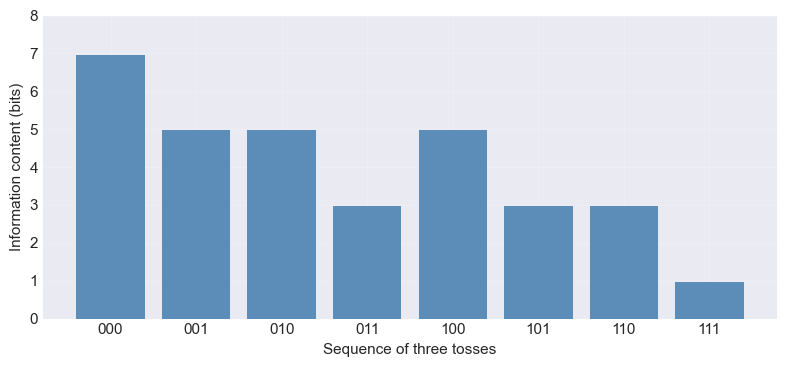

In [4]:
figure, axis = plt.subplots(figsize=(8, 3.8))

axis.bar(sequence_labels, sequence_information, color='#5B8DB8')
axis.set(
    xlabel='Sequence of three tosses',
    ylabel='Information content (bits)',
    ylim=(0, 8),
)

plt.tight_layout()
plt.show()

All eight sequences contain three binary digits, but their information content varies considerably. The sequence `111` is relatively unsurprising because heads are common, whereas `000` is much less likely and therefore carries much more information.

Notice that `011`, `101`, and `110` have the same information content. Each contains two heads and one tail, so their probabilities are equal even though the outcomes occur in a different order.

This doesn't mean that the sequence `000` takes nearly seven bits to write down. Any three-digit binary sequence can be written using three bits. Information content measures how surprising a particular sequence is under our biased coin model; the number of bits used to *encode* it is a separate question that we'll investigate later.

So far, we've calculated the information content of short sequences. But our original question concerns thousands of tosses. What can we say about the information content of a *long* sequence before we know its exact outcomes?

## Information Content of Longer Sequences

We've seen that two sequences of the same length can have very different information content. For our biased coin, a sequence containing more tails is less likely and therefore carries more information than one containing mostly heads.

But what happens as we increase the length of the sequence?

Since the information content of independent observations is additive, we can calculate the total information in a sequence of $N$ tosses by adding the information contributed by each head and tail.

If a sequence contains $k$ heads and $N-k$ tails, its information content is

$$I(\mathbf{x})=-k\log_2 p-(N-k)\log_2(1-p),$$

where $p$ is the probability of heads.

As we increase the number of tosses, the total information will generally increase as well. To compare sequences of different lengths, it makes more sense to calculate the information content *per toss*:

$$\frac{I(\mathbf{x})}{N}.$$

Let's simulate 10,000 independent sequences for each of four different lengths: 10, 100, 1,000, and 10,000 tosses.

For each sequence, we'll calculate its total information content and divide by the number of tosses.

In [5]:
sequence_lengths = [10, 100, 1_000, 10_000]
number_of_experiments = 10_000

coin_information = information_content(coin_probabilities)
information_by_length = {}

for sequence_length in sequence_lengths:
    head_counts = random_generator.binomial(
        sequence_length,
        heads_probability,
        size=number_of_experiments,
    )

    tail_counts = sequence_length - head_counts

    total_information = (
        head_counts * coin_information[1]
        + tail_counts * coin_information[0]
    )

    information_by_length[sequence_length] = (
        total_information / sequence_length
    )

    print(
        f"N = {sequence_length:>6,}: "
        f"mean = {information_by_length[sequence_length].mean():.4f}, "
        f"std = {information_by_length[sequence_length].std():.4f}"
    )

N =     10: mean = 0.7276, std = 0.2542
N =    100: mean = 0.7211, std = 0.0795
N =  1,000: mean = 0.7215, std = 0.0252
N = 10,000: mean = 0.7220, std = 0.0080


We don't need to generate and store every individual binary sequence here. Since the tosses are independent and have the same bias, information content depends only on the number of heads and tails. Drawing the head count from a binomial distribution therefore produces the same distribution of information content more efficiently.

Let's plot the information content per toss for each sequence length. The dashed line shows the true entropy of the coin, which we calculated in the previous article.

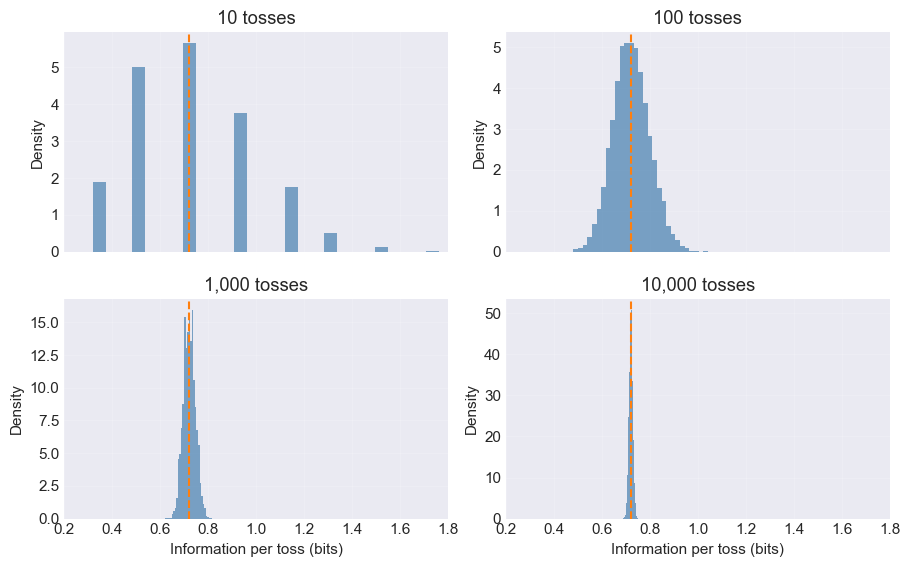

In [6]:
true_entropy = np.sum(coin_probabilities * coin_information)

figure, axes = plt.subplots(
    2, 2, figsize=(9, 5.8), sharex=True
)

for axis, (n, values) in zip(
    axes.flat, information_by_length.items()
):
    axis.hist(
        values,
        bins=30,
        density=True,
        color='#5B8DB8',
        alpha=0.8,
    )

    axis.axvline(
        true_entropy,
        linestyle='--',
        color='C1',
    )

    axis.set(
        title=f'{n:,} tosses',
        ylabel='Density',
        xlim=(0.2, 1.8),
    )

for axis in axes[-1]:
    axis.set_xlabel('Information per toss (bits)')

plt.tight_layout()
plt.show()

The difference between short and long sequences is striking.

For sequences of just ten tosses, the information content per toss varies considerably. Some sequences contain an unusually large number of tails and therefore carry much more information than others.

As we increase the sequence length, however, the distribution becomes increasingly concentrated around 0.722 bits per toss.

This value should look familiar. It's the Shannon entropy of our biased coin.

Recall that entropy is the *expected information content of a single toss*. If we repeatedly toss the same coin independently, the information content of each toss is another observation drawn from the same distribution.

The Law of Large Numbers tells us that the average of these observations approaches their expected value as the number of tosses increases.

In our case, this means

$$\frac{I(X_1,\ldots,X_N)}{N}\longrightarrow H(X)$$

as $N$ increases.

Although individual tosses can provide very different amounts of information, the average information per toss becomes increasingly predictable over a long sequence.

For our biased coin, a sufficiently long sequence will therefore typically have an information content close to

$$I(X_1,\ldots,X_N)\approx 0.722N\text{ bits}.$$

This is an interesting result. We cannot predict the exact sequence of outcomes, but we can make an increasingly reliable prediction about its total information content.

What does this tell us about the probability of observing a particular sequence? And why should it help us compress data?

## The Asymptotic Equipartition Property

In the previous experiment, we saw that the information content per toss becomes increasingly concentrated around the entropy of the coin as the sequence gets longer.

Recall that the information content of a sequence is defined as

$$I(\mathbf{x})=-\log_2P(\mathbf{x}),$$

where $P(\mathbf{x})$ is the probability of observing that particular sequence.

We also established that, for a sufficiently long sequence of independent tosses, its information content per toss is likely to be close to the entropy:

$$\frac{I(\mathbf{x})}{N}\approx H(X).$$

Substituting our definition of information content,

$$-\frac{1}{N}\log_2P(\mathbf{x})\approx H(X).$$

Rearranging,

$$\log_2P(\mathbf{x})\approx-NH(X).$$

Taking the power of two on both sides gives us

$$\boxed{P(\mathbf{x})\approx 2^{-NH(X)}.}$$

This is a remarkable result. Although we cannot predict the exact sequence of heads and tails, we can predict the approximate probability of the sequence we are likely to observe, at least on a logarithmic scale.

For our biased coin, the entropy is approximately 0.722 bits per toss. A sequence of 1,000 tosses with information content close to the expected value would therefore have a probability on the order of

$$P(\mathbf{x})\approx 2^{-722}.$$

That's an extraordinarily small probability. But remember that we're talking about the probability of one particular ordered sequence of 1,000 tosses, not the probability of observing any sequence at all.

Let's generate such a sequence and compare its actual information content with our prediction.

In [7]:
sequence_length = 1_000

sequence = random_generator.binomial(
    1, heads_probability, size=sequence_length
)

log_probability = np.log2(
    coin_probabilities[sequence]
).sum()

observed_information = -log_probability / sequence_length
expected_information = true_entropy

print(f"Heads observed: {sequence.sum()}")
print(f"Observed information per toss: {observed_information:.4f} bits")
print(f"Expected information per toss: {expected_information:.4f} bits")
print(f"Log₂ sequence probability: {log_probability:.2f}")
print(f"AEP reference (-NH): {-sequence_length * true_entropy:.2f}")

Heads observed: 809
Observed information per toss: 0.7039 bits
Expected information per toss: 0.7219 bits
Log₂ sequence probability: -703.93
AEP reference (-NH): -721.93


The observed information content is close to the expected value of 0.722 bits per toss. Small deviations are natural: even over 1,000 tosses, the observed proportion of heads need not equal 0.8 exactly.

The agreement becomes more reliable as the sequence length increases. This is a consequence of the Law of Large Numbers, applied to the information content of each toss.

The result is known as the *Asymptotic Equipartition Property*, or AEP.

More precisely, for a sequence of independent, identically distributed observations, AEP tells us that

$$-\frac{1}{N}\log_2P(X_1,\ldots,X_N)\longrightarrow H(X)$$

as the sequence length increases, with probability one.

This does not mean that every possible sequence has the same probability. Nor does it mean that the probability of a sequence becomes numerically equal to $2^{-NH(X)}$.

Rather, for any tolerance $\epsilon>0$, the probability of observing a sequence satisfying

$$H(X)-\epsilon\leq-\frac{1}{N}\log_2P(\mathbf{x})\leq H(X)+\epsilon$$

approaches one as $N$ increases.

Equivalently, such sequences have probabilities satisfying

$$2^{-N(H(X)+\epsilon)}\leq P(\mathbf{x})\leq2^{-N(H(X)-\epsilon)}.$$

In other words, most sufficiently long sequences generated by our coin have an information content per toss close to its entropy.

But this raises an interesting question.

If the probability of any particular long sequence is extraordinarily small, how can we be reasonably confident that the sequence we observe will have an information content close to the entropy?

The answer lies in how many different sequences have this property.